# Etude de l'early dropout sur un problème de régression
Le dataset California Housing contient des données relatives à des groupes de logements en Californie, issues du recensement américain de 1990. La variable à prédire est le prix médian des groupe de logements exprimé en centaine de milliers de dollar. Nous avons 8 variables explicatives qui donnent des informations sur le groupe de maisons.

Nous étudions d'abord si l'early dropout peut en effet aider les modèles en sous-apprentissage. Puis nous cherchons ce que veut dire early? 1%? 10%? 30%? Et nous analyserons l'effet de la taille du batch sur l'early dropout.

Etapes du travail:

1. **Calibration** - Trouver un régime de sous-apprentissage.
2. **Grille early dropout** - Entraînement sur différentes fractions d'early dropout.
3. **Batch size** - Entraînement sur différentes taille de batch.

In [137]:
import os, glob
import pandas as pd
import torch
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from config import BATCH, P, EARLY_GRID
from models import mlp
from train import entrainer_regression

In [138]:
X, y = fetch_california_housing(return_X_y=True)      # télécharge au premier appel (Internet requis), puis cache
print(X.shape, y.shape)                                # (20640, 8) (20640,)

# 60 % train / 20 % val / 20 % test (splits fixes)
X_train, X_tmp, y_train, y_tmp = train_test_split(X, y, test_size=0.4, random_state=1)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.5, random_state=1)

# normalisation avec les stats du train uniquement (en numpy, avant la conversion en tenseurs)
sx = StandardScaler().fit(X_train)
X_train, X_val, X_test = sx.transform(X_train), sx.transform(X_val), sx.transform(X_test)

# cibles standardisées aussi : MSE en unités d'écart-type², R² ≈ 1 - MSE
y_mu, y_sd = y_train.mean(), y_train.std()
y_train, y_val, y_test = [(a - y_mu) / y_sd for a in (y_train, y_val, y_test)]

to_t = lambda a: torch.tensor(a, dtype=torch.float32)
data = dict(Xtr=to_t(X_train), ytr=to_t(y_train), Xva=to_t(X_val), yva=to_t(y_val),
            Xte=to_t(X_test), yte=to_t(y_test))
print(data["Xtr"].shape, data["Xva"].shape, data["Xte"].shape)

(20640, 8) (20640,)
torch.Size([12384, 8]) torch.Size([4128, 8]) torch.Size([4128, 8])


## Paramètres propres à ce cadre

In [139]:
CADRE = "mlp_california"
OUT = "resultats"
os.makedirs(OUT, exist_ok=True)

Dans cette étude nous n'utiliserons que des modèles MLP avec deux couches cachées. Comme fonction de loss nous utilisons le MSE, comme métrique de performance d'un modèle nous utilisons le R2, l'optimizer utilisé est Adam. Nous fixons le batch size à 128 et le dropout rate à 0.1.


Nous commencons par trouver un modèle en sous-apprentissage, pour cela nous faisons varier la taille du modèle (nombre de neurones dans les deux couches cachées), avec le nombre d'epoch pour que le modèle ait fini d'apprendre.

## 1. Calibration du nombre d'epochs et de la largeur du modèle
On entraîne le même modèle sans dropout puis avec dropout standard, et on regarde la différence de R² de validation (le delta, en points).
Le dropout standard retire de la capacité au modèle.

- Si le modèle surapprend, retirer de la capacité l'aide : delta > 0.
- Si le modèle sous-apprend, il manque déjà de capacité, et en retirer encore le pénalise : delta < 0.

In [140]:
CALIB_WIDTHS = [8, 16, 32, 64]                  # largeurs des couches cachées
CALIB_EPOCHS = [10, 20, 50, 100]                # nombre d'epochs d'entraînement
CALIB_GRID = [0, 1]                             # 0 = sans dropout, 1 = dropout standard
CALIB_SEEDS = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]    # différentes seeds  


# Entrainement et sauvegarde des résultats
for WIDTH in CALIB_WIDTHS:
    for EPOCHS in CALIB_EPOCHS:
        for frac in CALIB_GRID:
            for seed in CALIB_SEEDS:
                fichier = f"{OUT}/{CADRE}_w{WIDTH}_e{EPOCHS}_frac{frac}_s{seed}.csv"
                if os.path.exists(fichier):
                    continue
                torch.manual_seed(seed)
                model, opt = mlp(8, 1, couche_cache=WIDTH)        # 8 features, 1 sortie
                hist = entrainer_regression(model, opt, data, EPOCHS, t_early=round(frac * EPOCHS),
                                            p=P, batch=BATCH)
                hist.assign(cadre=CADRE, width=WIDTH, epochs=EPOCHS, frac=frac, seed=seed).to_csv(fichier, index=False)
                print(f"w{WIDTH} e{EPOCHS} frac {frac} seed {seed}  val R² {hist.val_r2.iloc[-1]:.4f}")

In [141]:
cal = pd.concat(pd.read_csv(f) for f in glob.glob(f"{OUT}/{CADRE}_w*_e*_frac*_s*.csv"))
cal = cal[cal.width.isin(CALIB_WIDTHS) & cal.epochs.isin(CALIB_EPOCHS) & cal.frac.isin(CALIB_GRID) & cal.seed.isin(CALIB_SEEDS)]

# valeur finale = moyenne des 5 dernières epochs de chaque run
fin = (cal[cal.epoch >= cal.epochs - 5]
       .groupby(["width", "epochs", "frac", "seed"])[["train_loss", "val_loss", "val_r2"]].mean()
       .reset_index())

t = fin.pivot_table(index=["width", "epochs", "seed"], columns="frac", values="val_r2")
t["delta"] = (t[1] - t[0]) * 100                         # standard dropout- aucun dropout, en points de R²

# remontée relative de la loss de validation sans dropout, sur la moyenne glissante (fenêtre de 5 epochs) :
# (dernière fenêtre - meilleure fenêtre) / meilleure fenêtre
# 0 = la val loss est encore à son minimum à la fin ; plus c'est grand, plus elle a remonté (début de surapprentissage)
rem = {}
for (w, e, s), d in cal[cal.frac == 0].groupby(["width", "epochs", "seed"]):
    sm = d.sort_values("epoch").val_loss.rolling(5).mean().dropna()
    rem[(w, e, s)] = (sm.iloc[-1] - sm.min()) / sm.min()
rem = pd.Series(rem)
rem.index.names = ["width", "epochs", "seed"]

tab = t.groupby(["width", "epochs"]).agg(
    r2_sans_dropout=(0, "mean"),
    r2_avec_dropout=(1, "mean"),
    delta_moy=("delta", "mean"),
    delta_min=("delta", "min"),
    delta_max=("delta", "max"),
)
tab["remontee_val_loss"] = rem.groupby(["width", "epochs"]).mean()
tab["sous_apprentissage"] = tab.delta_max <= -0.5        
tab["pas_de_surapprentissage"] = tab.remontee_val_loss < 0.02      # moins de 2 % de remontée
tab = tab.round(3)
display(tab)

r2_sans_dropout  r2_avec_dropout  delta_moy  delta_min  \
width epochs                                                           
8     10                0.645            0.621     -2.458     -3.452   
      20                0.686            0.669     -1.684     -2.186   
      50                0.719            0.706     -1.304     -1.705   
      100               0.734            0.720     -1.357     -2.469   
16    10                0.673            0.659     -1.431     -1.904   
      20                0.705            0.690     -1.479     -2.051   
      50                0.737            0.724     -1.280     -2.003   
      100               0.753            0.742     -1.150     -2.003   
32    10                0.688            0.677     -1.075     -1.590   
      20                0.719            0.709     -1.025     -1.544   
      50                0.758            0.745     -1.271     -1.656   
      100               0.771            0.765     -0.621     -1.096   
64    10                0.706            0.695     -1.040     -1.359   
      20                0.741            0.730     -1.120     -1.555   
      50                0.769            0.763     -0.575     -0.796   
      100               0.779            0.781      0.223     -0.160   

              delta_max  remontee_val_loss  sous_apprentissage  \
width epochs                                                     
8     10         -1.128                0.0                True   
      20         -0.926                0.0                True   
      50         -0.198                0.0               False   
      100        -0.263                0.0               False   
16    10         -1.036                0.0                True   
      20         -1.062                0.0                True   
      50         -0.813                0.0                True   
      100         0.019                0.0               False   
32    10         -0.664                0.0                True   
      20         -0.592                0.0                True   
      50         -0.536                0.0                True   
      100        -0.209                0.0               False   
64    10         -0.811                0.0                True   
      20         -0.810                0.0                True   
      50         -0.295                0.0               False   
      100         0.864                0.0               False   

              pas_de_surapprentissage  
width epochs                           
8     10                         True  
      20                         True  
      50                         True  
      100                        True  
16    10                         True  
      20                         True  
      50                         True  
      100                        True  
32    10                         True  
      20                         True  
      50                         True  
      100                        True  
64    10                         True  
      20                         True  
      50                         True  
      100                        True

Une configuration est retenue comme sous-apprentissage si toutes les graines ont un delta ≤ -0.5, pour être certain.

On observe que le modèle de largeur 8 entraîné sur 10 epochs est celui qui perd le plus de capacité avec dropout. Le modèle est clairement limité par sa capacité: plus la largeur du modèle augmente plus le r2 augmente. 

On décide de comparer l'effet de l'early dropout sur le modèle en sous-apprentissage le plus gros avec le plus d'epochs: width=32, epoch=50.



## 2. Entraînement sur différentes valeurs d'early dropout: 5%, 10%, 20%, 30%, 50%.

In [142]:
WIDTH = 32 
EPOCHS = 50
SEEDS = list(range(5))
EARLY_GRID = [0, 0.05, 0.1, 0.2, 0.3, 0.5, 1]

print(EPOCHS, "epochs :", [round(frac * EPOCHS) for frac in EARLY_GRID], "epochs de dropout")

50 epochs : [0, 2, 5, 10, 15, 25, 50] epochs de dropout


In [143]:
#(un CSV par run, les runs déjà faits sont sautés)
for frac in EARLY_GRID:
    for seed in SEEDS:
        fichier = f"{OUT}/{CADRE}_w{WIDTH}_e{EPOCHS}_frac{frac}_s{seed}.csv"
        if os.path.exists(fichier):
            continue
        torch.manual_seed(seed)
        model, opt = mlp(8, 1, couche_cache=WIDTH)
        hist = entrainer_regression(model, opt, data, EPOCHS, t_early=round(frac * EPOCHS),
                                    p=P, batch=BATCH)
        hist.assign(cadre=CADRE, width=WIDTH, epochs=EPOCHS, frac=frac, seed=seed).to_csv(fichier, index=False)
        print(f"e{EPOCHS} frac {frac:<4} seed {seed}  val R² {hist.val_r2.iloc[-1]:.4f}")

### Analyse : relit tous les CSV de ce cadre

In [144]:
# Analyse appariée pour width=32 et 50 epochs.
ANALYSIS_EPOCHS = {32: [50]}
T95 = {5: 2.78}  # quantile de Student à 95 %

comp_by_width = {}
tab_by_width = {}

for width, epochs_list in ANALYSIS_EPOCHS.items():
    comp_runs = []
    for E in epochs_list:
        fichiers = glob.glob(f"{OUT}/{CADRE}_w{width}_e{E}_frac*_s*.csv")
        if not fichiers:
            raise FileNotFoundError(f"Aucun CSV trouvé pour width={width}, epochs={E}")

        d = pd.concat((pd.read_csv(fp) for fp in fichiers), ignore_index=True)
        d = d[d.seed.isin(SEEDS) & d.frac.isin(EARLY_GRID)]
        fe = (d[d.epoch >= E - 5]
              .groupby(["frac", "seed"])[["train_loss", "val_r2", "test_r2"]].mean()
              .reset_index())

        if set(fe.frac) != set(EARLY_GRID):
            raise ValueError(f"Fractions incomplètes pour width={width}, epochs={E}")
        base = fe[fe.frac == 0].set_index("seed")
        expected_seeds = set(SEEDS)
        for frac, group in fe.groupby("frac"):
            if set(group.seed) != expected_seeds:
                raise ValueError(
                    f"Graines incomplètes pour width={width}, epochs={E}, frac={frac}"
                )
        if set(base.index) != expected_seeds:
            raise ValueError(f"Baseline sans dropout incomplète pour width={width}, epochs={E}")
        for col in ["train_loss", "val_r2", "test_r2"]:
            fe[f"d_{col}"] = fe[col] - fe.seed.map(base[col])
        fe["epochs"] = E
        comp_runs.append(fe)

    comp = pd.concat(comp_runs, ignore_index=True)
    comp_by_width[width] = comp

    def ic95(values):
        n = len(values)
        if n != len(SEEDS) or n not in T95:
            raise ValueError(f"Il faut exactement {len(SEEDS)} graines pour calculer l'IC à 95 % (reçu {n})")
        return T95[n] * values.std() / n ** 0.5

    stats = comp.groupby(["epochs", "frac"]).agg(
        gain_val=("d_val_r2", lambda x: 100 * x.mean()),
        ic_val=("d_val_r2", lambda x: 100 * ic95(x)),
        gain_test=("d_test_r2", lambda x: 100 * x.mean()),
        ic_test=("d_test_r2", lambda x: 100 * ic95(x)),
        d_train_loss=("d_train_loss", "mean"),
        ic_train_loss=("d_train_loss", ic95),
    )
    tab_by_width[width] = stats

for width, table in tab_by_width.items():
    print(f"Width={width}")
    display(table.round(4))

Width=32


gain_val  ic_val  gain_test  ic_test  d_train_loss  ic_train_loss
epochs frac                                                                   
50     0.00    0.0000  0.0000     0.0000   0.0000        0.0000         0.0000
       0.05   -0.1370  0.1005    -0.1546   0.2768        0.0013         0.0018
       0.10   -0.2653  0.3389    -0.2324   0.3514        0.0022         0.0035
       0.20   -0.2517  0.4086    -0.2197   0.5349        0.0025         0.0053
       0.30   -0.3403  0.3513    -0.2966   0.4980        0.0035         0.0050
       0.50   -0.6589  0.3286    -0.6682   0.5258        0.0075         0.0050
       1.00   -1.3966  0.2033    -1.6312   0.4833        0.0179         0.0046

La cellule suivante affiche, pour le modèle MLP de largeur 32 entraîné pendant 50 epochs, les gains de R² en validation et en test (R² early dropout - R² sans dropout), ainsi que l'écart de loss d'entraînement (early dropout - sans dropout). Chaque point compare les runs graine par graine; les barres montrent l'intervalle de confiance à 95 % de ces différences appariées, calculé sur les graines définies dans `SEEDS` (quantile de Student, n−1 degrés de liberté).

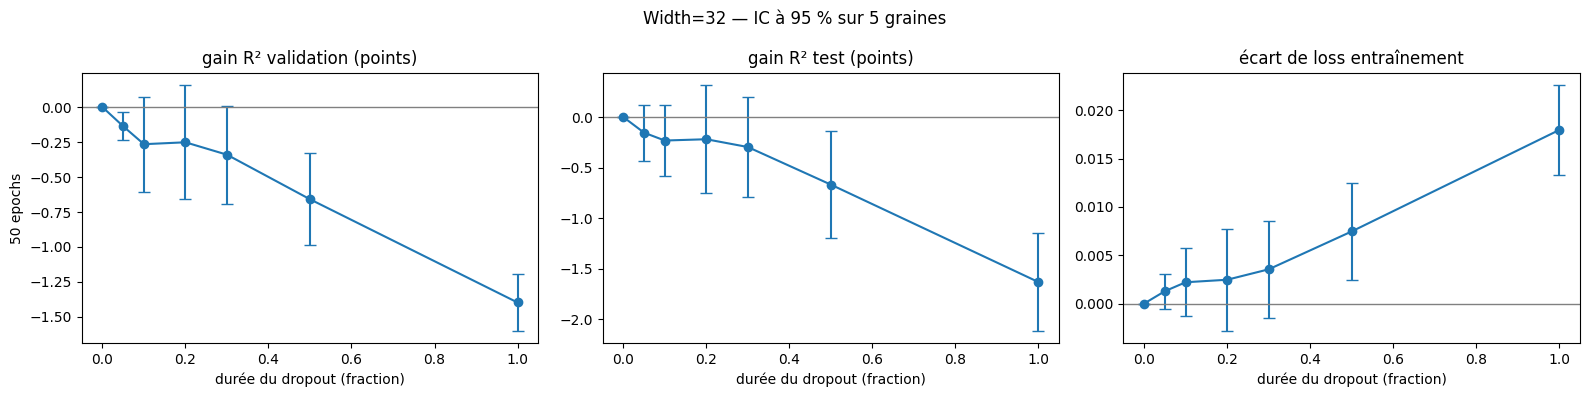

In [145]:
# Graphiques pour chaque width
for W in ANALYSIS_EPOCHS:
    stats = tab_by_width[W]
    fig, axes = plt.subplots(
        len(ANALYSIS_EPOCHS[W]), 3,
        figsize=(16, 4 * len(ANALYSIS_EPOCHS[W])), sharey="col", squeeze=False,
    )
    for r, E in enumerate(ANALYSIS_EPOCHS[W]):
        t = stats.xs(E, level="epochs")
        axes[r, 0].errorbar(t.index, t.gain_val, yerr=t.ic_val, marker="o", capsize=4)
        axes[r, 1].errorbar(t.index, t.gain_test, yerr=t.ic_test, marker="o", capsize=4)
        axes[r, 2].errorbar(t.index, t.d_train_loss, yerr=t.ic_train_loss, marker="o", capsize=4)
        axes[r, 0].set_ylabel(f"{E} epochs")
        for ax in axes[r]:
            ax.axhline(0, color="gray", lw=1)
            ax.set_xlabel("durée du dropout (fraction)")
    axes[0, 0].set_title("gain R² validation (points)")
    axes[0, 1].set_title("gain R² test (points)")
    axes[0, 2].set_title("écart de loss entraînement")
    fig.suptitle(f"Width={W} — IC à 95 % sur {len(SEEDS)} graines")
    fig.tight_layout()
    plt.show()

### Bilan

Chaque point compare une fraction d'early dropout au modèle sans dropout, graine par graine. Un gain positif de R² indique une amélioration; pour la loss d'entraînement, une différence négative est préférable. Les barres représentent les intervalles de confiance à 95 %. Lorsqu'un intervalle recouvre zéro, les résultats ne permettent pas de conclure à un effet net. Cela ne prouve pas l'absence d'effet, mais indique que l'effet observé reste incertain avec 5 graines.

Sur ces graphiques nous voyons que l'early dropout à plutôt tendance à rendre le modèle moins bon. Le R2 est moins bon en moyenne en test et en validation. La train loss est plus grande en moyenne. Ces effets s'accentue quand la fraction d'early dropout s'aggrandie.

Aucune fraction ne démontre à 95 % une amélioration de la loss d'entraînement ou du R² en validation ou en test. C'est même le contraire.

## 3. Étude de l'influence du batch size

On garde le même modèle width=32, 50 epochs, les mêmes fractions d'early dropout et les mêmes cinq graines. Seul le batch size varie. Cela garde constant le nombre de passages sur les données, mais le nombre de mises à jour de l'optimiseur varie : on le calcule pour chaque configuration et on l'utilise comme abscisse des graphiques. Cette comparaison mesure donc l'effet pratique du batch size à epochs fixes; elle ne sépare pas l'effet du batch size de celui du nombre total de mises à jour.

In [146]:
import math

WIDTH = 32
EPOCHS = 50
BATCH_STUDY_SIZES = [8, 16, 32, 64, 128, 256, 512]
n_train = len(data["Xtr"])

for bs in BATCH_STUDY_SIZES:
    steps_per_epoch = math.ceil(n_train / bs)
    for frac in EARLY_GRID:
        for seed in SEEDS:
            fichier = (f"{OUT}/{CADRE}_batchsize_w{WIDTH}_"
                       f"e{EPOCHS}_bs{bs}_frac{frac}_s{seed}.csv")
            if os.path.exists(fichier):
                continue

            torch.manual_seed(seed)
            model, opt = mlp(8, 1, couche_cache=WIDTH)
            t_early = round(frac * EPOCHS)
            hist = entrainer_regression(
                model, opt, data, EPOCHS, t_early=t_early,
                p=P, batch=bs,
            )
            hist.assign(
                cadre=CADRE, width=WIDTH, epochs=EPOCHS,
                batch=bs, frac=frac, seed=seed,
                updates_per_epoch=steps_per_epoch,
                early_updates=t_early * steps_per_epoch,
            ).to_csv(fichier, index=False)
            print(f"batch={bs}, frac={frac}, seed={seed}: "
                  f"{t_early * steps_per_epoch} mises à jour avec dropout")

Commencons par regarder si avec ces nouvelle taille de batch, nous sommes toujours en régime de sous-apprentissage.

In [148]:
# Même critère que la calibration : la baisse de R² validation avec dropout standard doit être d'au moins 0,5 point pour toutes les graines.
underfit_runs = pd.concat(
    pd.read_csv(fp) for fp in glob.glob(
        f"{OUT}/{CADRE}_batchsize_w{WIDTH}_e{EPOCHS}_bs*_frac*_s*.csv"
    )
)
underfit_runs = underfit_runs[
    underfit_runs.batch.isin(BATCH_STUDY_SIZES)
    & underfit_runs.frac.isin([0, 1])
    & underfit_runs.seed.isin(SEEDS)
]
underfit_final = (
    underfit_runs[underfit_runs.epoch >= EPOCHS - 5]
    .groupby(["batch", "frac", "seed"]).val_r2.mean()
    .unstack("frac")
)
underfit_final["delta_val_r2"] = (underfit_final[1] - underfit_final[0]) * 100
underfit_table = underfit_final.groupby("batch").delta_val_r2.max().to_frame(
    "delta max R² validation (points)"
)
underfit_table["sous-apprentissage"] = underfit_table["delta max R² validation (points)"] <= -0.5
display(underfit_table.round(3))

,delta max R² validation (points),sous-apprentissage
batch,,
8,-0.459,False
16,-0.141,False
32,-0.337,False
64,-0.611,True
128,-1.259,True
256,-1.108,True
512,-0.776,True


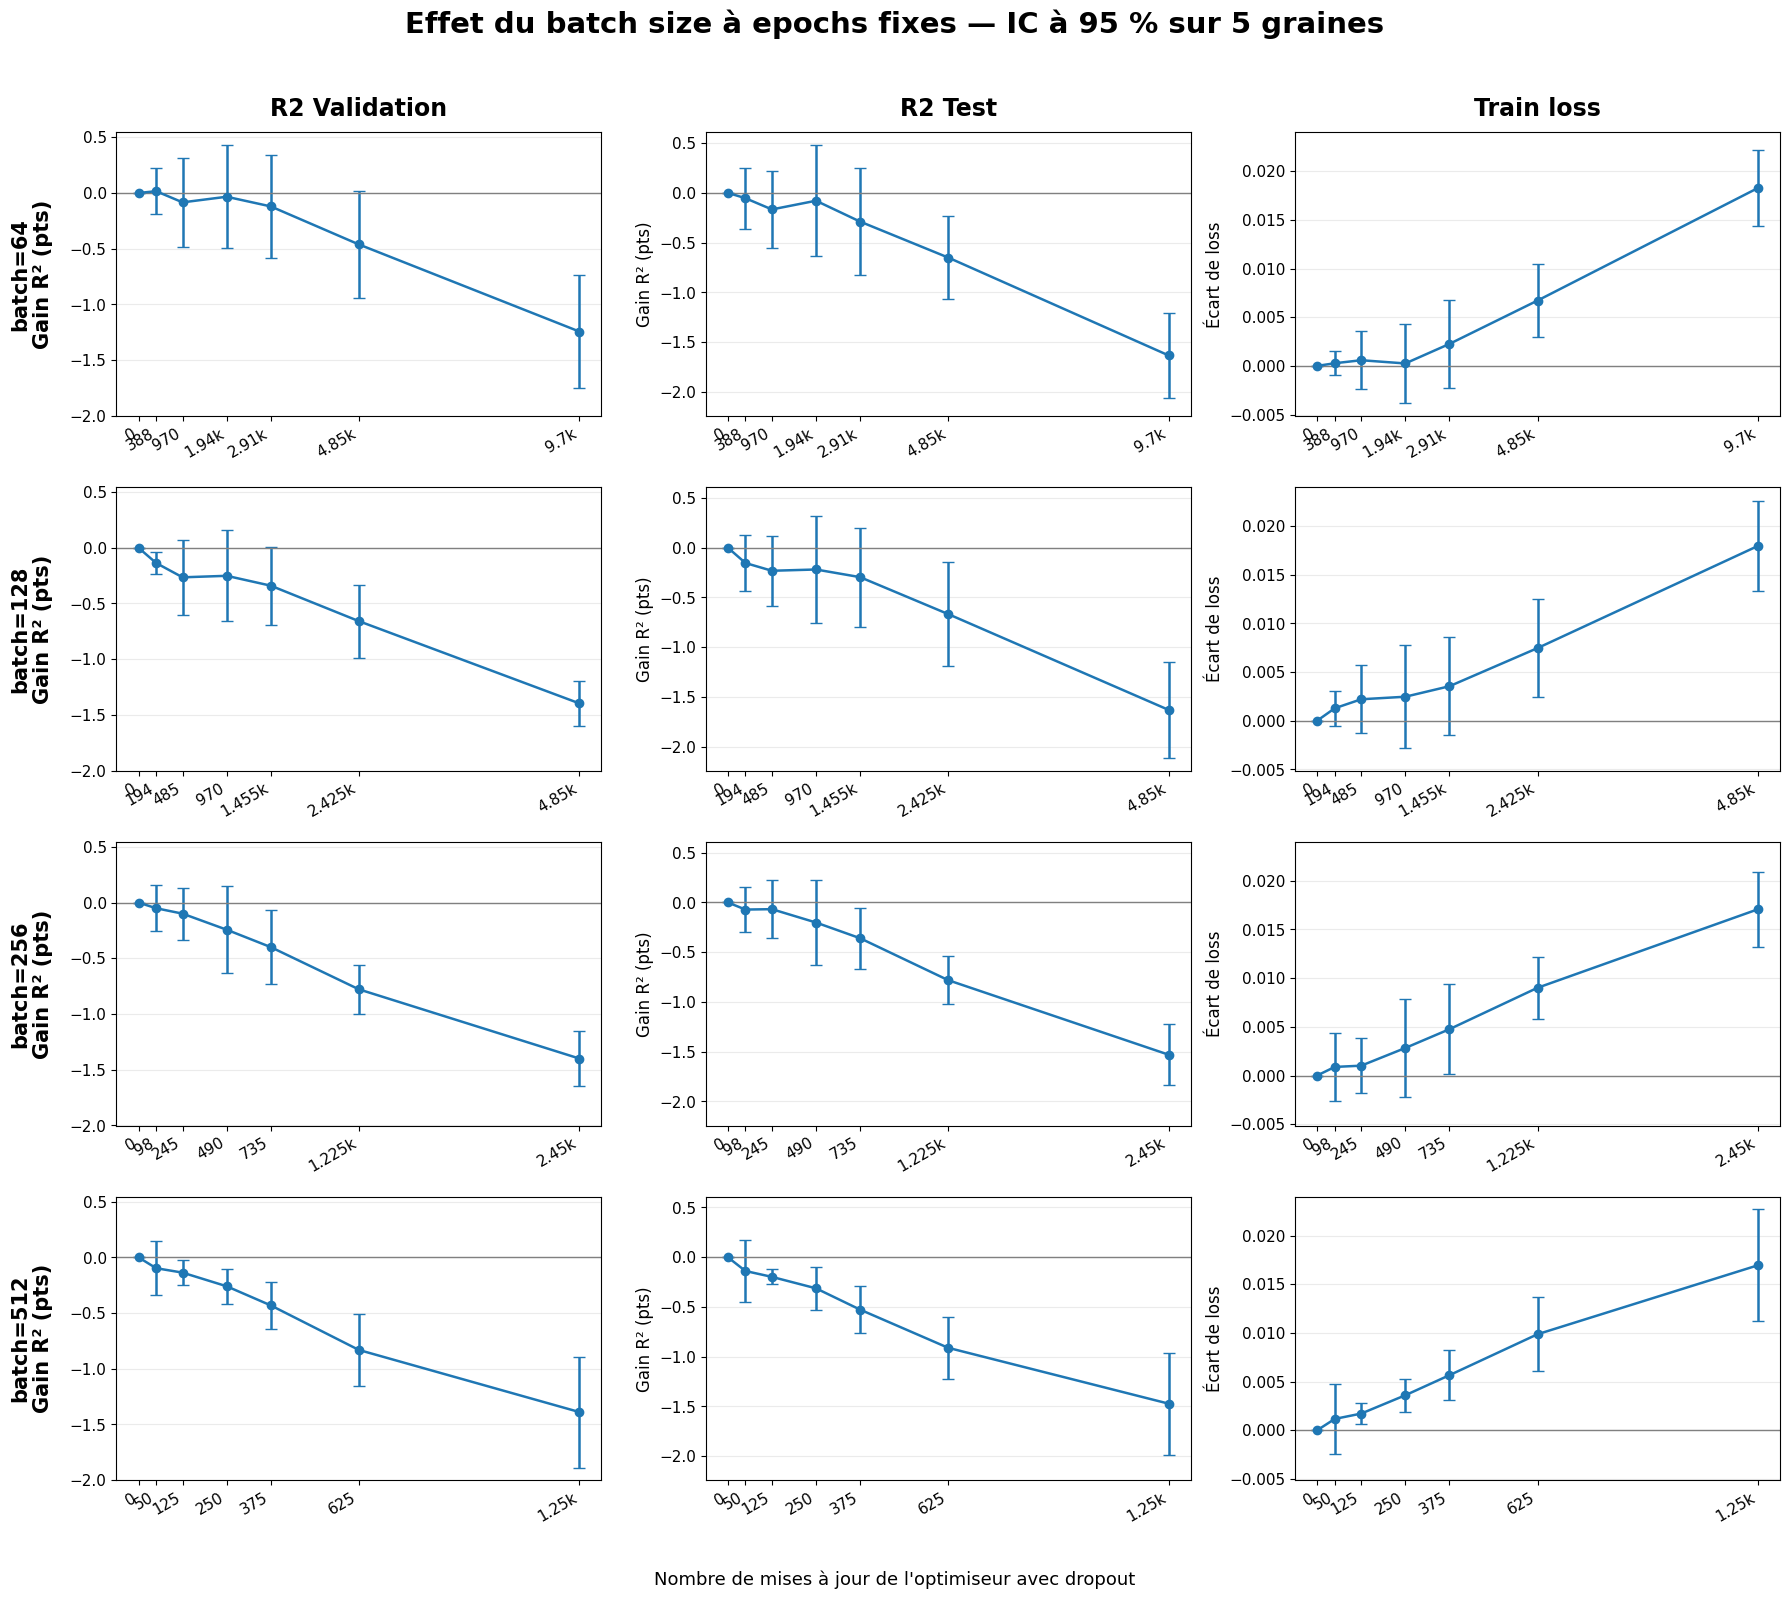

In [149]:
# Gains appariés au modèle sans dropout du même batch size et de la même graine.
batch_files = glob.glob(
    f"{OUT}/{CADRE}_batchsize_w{WIDTH}_e{EPOCHS}_bs*_frac*_s*.csv"
)
if not batch_files:
    raise FileNotFoundError("Aucun résultat batch size trouvé; exécuter la cellule d'entraînement d'abord.")

batch_runs = pd.concat((pd.read_csv(fp) for fp in batch_files), ignore_index=True)
batch_runs = batch_runs[
    batch_runs.batch.isin(BATCH_STUDY_SIZES)
    & batch_runs.frac.isin(EARLY_GRID)
    & batch_runs.seed.isin(SEEDS)
]
batch_final = (
    batch_runs[batch_runs.epoch >= EPOCHS - 5]
    .groupby(["batch", "frac", "seed"])[["train_loss", "val_r2", "test_r2"]]
    .mean()
    .reset_index()
)

batch_baseline = batch_final[batch_final.frac == 0][
    ["batch", "seed", "train_loss", "val_r2", "test_r2"]
].rename(columns={
    "train_loss": "baseline_train_loss",
    "val_r2": "baseline_val_r2",
    "test_r2": "baseline_test_r2",
})
batch_comp = batch_final.merge(
    batch_baseline, on=["batch", "seed"], how="left", validate="many_to_one"
)
if batch_comp[["baseline_train_loss", "baseline_val_r2", "baseline_test_r2"]].isna().any().any():
    raise ValueError("Il manque une baseline sans dropout pour au moins une combinaison batch/graine.")

batch_comp["d_train_loss"] = batch_comp.train_loss - batch_comp.baseline_train_loss
batch_comp["d_val_r2"] = batch_comp.val_r2 - batch_comp.baseline_val_r2
batch_comp["d_test_r2"] = batch_comp.test_r2 - batch_comp.baseline_test_r2
batch_counts = batch_comp.groupby(["batch", "frac"]).seed.nunique()
if not batch_counts.eq(len(SEEDS)).all():
    raise ValueError("Chaque batch size et fraction doit avoir les cinq graines prévues.")

batch_comp["early_updates"] = [
    round(frac * EPOCHS) * math.ceil(n_train / bs)
    for bs, frac in zip(batch_comp.batch, batch_comp.frac)
]

def ic95_batch(values):
    n = len(values)
    if n not in T95:
        raise ValueError(f"Nombre de graines inattendu pour l'IC à 95 % : {n}")
    return T95[n] * values.std() / n ** 0.5

batch_stats = batch_comp.groupby(["batch", "frac"]).agg(
    early_updates=("early_updates", "first"),
    gain_val=("d_val_r2", lambda x: 100 * x.mean()),
    ic_val=("d_val_r2", lambda x: 100 * ic95_batch(x)),
    gain_test=("d_test_r2", lambda x: 100 * x.mean()),
    ic_test=("d_test_r2", lambda x: 100 * ic95_batch(x)),
    d_train_loss=("d_train_loss", "mean"),
    ic_train_loss=("d_train_loss", ic95_batch),
)

PLOT_BATCH_SIZES = [64, 128, 256, 512]
fig, axes = plt.subplots(
    len(PLOT_BATCH_SIZES), 3, figsize=(18, 4 * len(PLOT_BATCH_SIZES)),
    sharex="row", sharey="col", squeeze=False,
)
for row_index, bs in enumerate(PLOT_BATCH_SIZES):
    group = batch_stats.xs(bs, level="batch").sort_values("early_updates")
    updates = group.early_updates
    axes[row_index, 0].errorbar(
        updates, group.gain_val, yerr=group.ic_val, marker="o", capsize=4, linewidth=1.8,
    )
    axes[row_index, 1].errorbar(
        updates, group.gain_test, yerr=group.ic_test, marker="o", capsize=4, linewidth=1.8,
    )
    axes[row_index, 2].errorbar(
        updates, group.d_train_loss, yerr=group.ic_train_loss, marker="o", capsize=4, linewidth=1.8,
    )
    axes[row_index, 0].set_ylabel(f"batch={bs}\nGain R² (pts)", fontsize=15, fontweight="bold", labelpad=12)
    for ax in axes[row_index]:
        ax.axhline(0, color="gray", linewidth=1)
        ax.grid(axis="y", alpha=0.25)
        ax.tick_params(axis="both", labelsize=11)
        ax.set_xticks(updates)
        ax.set_xticklabels(
            [f"{value / 1000:g}k" if value >= 1000 else str(int(value)) for value in updates],
            rotation=30, ha="right",
        )
    axes[row_index, 1].set_ylabel("Gain R² (pts)", fontsize=12)
    axes[row_index, 2].set_ylabel("Écart de loss", fontsize=12)

axes[0, 0].set_title("R2 Validation", fontsize=17, fontweight="bold", pad=12)
axes[0, 1].set_title("R2 Test", fontsize=17, fontweight="bold", pad=12)
axes[0, 2].set_title("Train loss", fontsize=17, fontweight="bold", pad=12)
fig.suptitle("Effet du batch size à epochs fixes — IC à 95 % sur 5 graines",
             fontsize=21, fontweight="bold", y=0.997)
fig.supxlabel("Nombre de mises à jour de l'optimiseur avec dropout", fontsize=13)
fig.tight_layout(rect=(0, 0.02, 1, 0.98), h_pad=1.5)
plt.show()

### Interprétation de l'étude batch size

Chaque point compare l'early dropout à la configuration sans dropout, pour le même batch size et la même graine. Les métriques sont moyennées sur les cinq dernières epochs; les barres représentent des IC à 95 % calculés sur cinq graines. Un gain de R² positif est favorable; une différence de loss d'entraînement négative signifie une loss plus faible.

Premièrement, nous voyons qu'avec des tailles de batch différents à 128, le modèle est toujours en sous-apprentissage. Maintenant regardons l'early dropout améliore le modèle ou toujours pas.

A 64, l'early dropout sur les fractions 5%, 10% et 20% ne change quasiment pas le R2 en val et en test, pareil pour la train loss.

En augmentant la taille du batch, à 256 et 512, nous observons des performances très similaire au 128, mais cette fois-ci avec des intervalles de confiances qui ne contiennent pas 0, par exemple pour 512, avec early dropout 10% a un R2 plus faible en val et en test et que sa train loss est plus elevé.
